# State Space Models

## Conversions

In [22]:
%reload_ext autoreload
%autoreload 2

In [23]:
# Course utilities (do not modify this cell)
# Generated by post-canvas-notebooks. Edits above the marker are overwritten.
from pathlib import Path
import sys

def _find_courseutils():
    """Find courseutils no matter where the course repo was cloned."""
    here = Path.cwd().resolve()

    for parent in [here] + list(here.parents):
        for candidate in (parent / "courseutils",
                          parent / "Signals_and_Systems" / "courseutils"):
            if (candidate / "basic_material.py").is_file():
                return candidate.resolve()

    raise FileNotFoundError(
        "Could not find the 'courseutils' folder. Clone "
        "https://github.com/mit-acl/Signals_and_Systems and run this "
        "notebook from inside the cloned repository, then restart the kernel."
    )


COURSEUTILS_DIR = _find_courseutils()

# courseutils is used both as a folder of modules and as a package,
# since control_materials does "import courseutils.basic_material",
# so the folder and its parent both go on the path.
for _location in (COURSEUTILS_DIR.parent, COURSEUTILS_DIR):
    if str(_location) not in sys.path:
        sys.path.insert(0, str(_location))

for _folder in ("data", "figs"):
    Path(_folder).mkdir(exist_ok=True)

# --- end course setup ---

import basic_material as bm
print("Basic Material version:", bm.__version__)
bm.setup_environment()

import courseutils.control_materials as cm
cm.setup_environment()

Basic Material version: 16.002-0.1


## TF2SS

In [24]:
import numpy as np
import sympy 
sympy.init_printing()
print('sympy version '+sympy.__version__)

s = sympy.Symbol('s')

import control.matlab as ct
#from control.matlab import *

def near_zero(P, Tol = 1e-12):
    P.num[0][0] = [x if abs(x) > Tol else 0 for x in P.num[0][0]]
    return P

sympy version 1.13.3


In [25]:
s = ct.tf('s')
P = 4/(s**3 + 2*s**2 + 3*s + 4)

In [26]:
sys = ct.tf2ss(P)
print('A = \n',sys.A)
print('B = \n',sys.B)
print('C = \n',sys.C)
print('D = \n',sys.D)

A = 
 [[  -2.000   -3.000   -4.000]
 [   1.000    0.000    0.000]
 [   0.000    1.000    0.000]]
B = 
 [[   1.000]
 [   0.000]
 [   0.000]]
C = 
 [[   0.000    0.000    4.000]]
D = 
 [[   0.000]]


## SS2TF

In [27]:
PP = ct.ss2tf(sys)
PP = near_zero(PP)

In [28]:
cm.show_tf_latex(PP)            # G(s) = 4.00 / (s^3 + 2.00s^2 + 3.00s + 4.00)
cm.show_tf_latex(PP, factor=True)   # factored form
cm.show_ss_latex(sys)           # A, B, C, D as LaTeX matrices

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

# Compute the Matrix Exponential

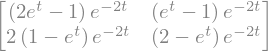

In [29]:
from sympy import symbols, Matrix, simplify, exp
n=2
A = Matrix([[0, 1], [-2, -3]])
t = symbols('t',real=True,positive=True);
simplify(exp(A*t))

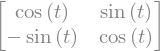

In [30]:
A = Matrix([[0, 1], [-1, 0]])
t = symbols('t',real=True,positive=True);
simplify(exp(A*t))

# Linearization about Equilibrium Points
Nonlinear dynamics $\dot{\mathbf x} = \mathbf f(\mathbf x)$ (Problem S11.1 from 2024):
$$
\frac{d}{dt}\begin{bmatrix} x_1 \\ x_2 \\ x_3 \end{bmatrix} =
\begin{bmatrix} x_2(x_3-x_1) \\ x_1^2-1 \\ x_2-x_1x_3 \end{bmatrix}
$$
**Step 1:** equilibrium points $\mathbf x_0$ satisfy $\mathbf f(\mathbf x_0) = \mathbf 0$.

In [31]:
x1, x2, x3 = sympy.symbols('x_1 x_2 x_3')
X = Matrix([x1, x2, x3])
f = Matrix([x2*(x3 - x1), x1**2 - 1, x2 - x1*x3])
eq_pts = sympy.solve(list(f), [x1, x2, x3], dict=True)
[tuple(X.subs(e)) for e in eq_pts]

**Step 2:** Taylor series. Let $\mathbf x = \mathbf x_0 + \epsilon\,\delta\mathbf x$ with $\epsilon$ small, expand $\mathbf f$ in powers of $\epsilon$:
$$
\mathbf f(\mathbf x_0 + \epsilon\,\delta\mathbf x) = \underbrace{\mathbf f(\mathbf x_0)}_{=\,0} + \epsilon\,\underbrace{\left.\frac{\partial \mathbf f}{\partial \mathbf x}\right|_{\mathbf x_0}}_{A}\delta\mathbf x + O(\epsilon^2)
$$
Since $\dot{\mathbf x} = \epsilon\,\delta\dot{\mathbf x}$, keeping the first-order terms gives $\delta\dot{\mathbf x} = A\,\delta\mathbf x$.
Below: the full expansion at $\mathbf x_0 = (1,1,1)$; the $\epsilon^2$ terms are the ones we drop.

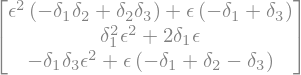

In [32]:
eps = sympy.Symbol('epsilon')
d1, d2, d3 = sympy.symbols('delta_1 delta_2 delta_3')
dX = Matrix([d1, d2, d3])

x0 = X.subs(eq_pts[3])                       # (1, 1, 1)
f_pert = f.subs(dict(zip(X, x0 + eps*dX)), simultaneous=True)
f_pert.applyfunc(lambda g: sympy.collect(sympy.expand(g), eps))

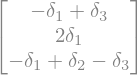

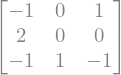

In [33]:
# keep only the O(eps) terms, then read off A as the coefficients of delta
f_lin = f_pert.applyfunc(lambda g: sympy.expand(g).coeff(eps, 1))
A0 = f_lin.jacobian(dX)
display(f_lin, A0)

**Step 3:** the same $A$ comes directly from the Jacobian $\partial \mathbf f/\partial \mathbf x$ evaluated at each equilibrium point. The eigenvalues of each $A$ give the local stability.

<IPython.core.display.Math object>

x0 = (-1, 0, 0)  eig = 0-1.414j, 0+1.414j, 1


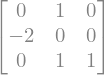

x0 = (-1, 1, -1)  eig = -1.769, 0.885-0.59j, 0.885+0.59j


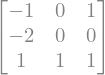

x0 = (1, 0, 0)  eig = 0-1.414j, 0+1.414j, -1


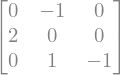

x0 = (1, 1, 1)  eig = -1.287-1.35j, 0.575, -1.287+1.35j


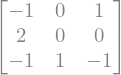

In [34]:
from IPython.display import Math
J = f.jacobian(X)
display(Math(r'\mathbf x_0 = ' + sympy.latex(tuple(X.subs(e))) + r',\quad A = ' + sympy.latex(A_e)))

def fmt(z):
    r, i = round(z.real, 3) + 0.0, round(z.imag, 3) + 0.0
    return f'{r:g}' if i == 0 else f'{r:g}{i:+g}j'

for e in eq_pts:
    A_e = J.subs(e)
    lam = [complex(v) for v in A_e.evalf().eigenvals(multiple=True)]
    print('x0 =', tuple(X.subs(e)), ' eig =', ', '.join(fmt(complex(v)) for v in lam))
    display(A_e)